In [1]:
##Import necessary libraries
import os 
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["OMP_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

In [2]:
RANDOM_STATE = 42
SELECTED_K = 2
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True, 'grid.alpha': 0.2})

In [3]:
## Load the Dataset
path = Path("uber-data.csv")
if not path.exists():
    path = Path("uber-data.csv.gz")
if not path.exists():
    raise FileNotFoundError("Upload uber-data.csv.gz or uber-data.csv to the notebook folder.")

data = pd.read_csv(path)
data.head()

,Date/Time,Lat,Lon,Base
0,9/1/2014 0:01:00,40.2201,-74.0021,B02512
1,9/1/2014 0:01:00,40.7500,-74.0027,B02512
2,9/1/2014 0:03:00,40.7559,-73.9864,B02512
3,9/1/2014 0:06:00,40.7450,-73.9889,B02512
4,9/1/2014 0:11:00,40.8145,-73.9444,B02512


In [4]:
## Convert the "Date/Time" column to datetime format and check for missing values
data["datetime"] = pd.to_datetime(data["Date/Time"],format="%m/%d/%Y %H:%M:%S", errors='coerce')
print("Rows:", f"{len(data):,}")
print("Missing values:")
print(data[["datetime", "Lat", "Lon"]].isnull().sum())
print(data.head())


Rows: 1,028,136
Missing values:
datetime    0
Lat         0
Lon         0
dtype: int64
          Date/Time      Lat      Lon    Base            datetime
0  9/1/2014 0:01:00  40.2201 -74.0021  B02512 2014-09-01 00:01:00
1  9/1/2014 0:01:00  40.7500 -74.0027  B02512 2014-09-01 00:01:00
2  9/1/2014 0:03:00  40.7559 -73.9864  B02512 2014-09-01 00:03:00
3  9/1/2014 0:06:00  40.7450 -73.9889  B02512 2014-09-01 00:06:00
4  9/1/2014 0:11:00  40.8145 -73.9444  B02512 2014-09-01 00:11:00


In [5]:
## Filter the data to include only valid records within the specified geographic bounds
valid = (
    data["datetime"].notna()
    & data["Lat"].between(40.40, 41.10)
    & data["Lon"].between(-74.50, -73.40)
)
rides = data.loc[valid].copy()
print("Rows used:", f"{len(rides):,}")
print("Rows excluded:", f"{len(data) - len(rides):,}")
print("First and last record:", rides["datetime"].min(), "—", rides["datetime"].max())

# A local, approximate conversion to kilometres. This makes X and Y comparable.
lat_reference = rides["Lat"].mean()
lon_reference = rides["Lon"].mean()
cos_lat = np.cos(np.deg2rad(lat_reference))
X = np.column_stack([
    (rides["Lon"].to_numpy() - lon_reference) * 111.32 * cos_lat,
    (rides["Lat"].to_numpy() - lat_reference) * 111.32
])


Rows used: 1,027,382
Rows excluded: 754
First and last record: 2014-09-01 00:00:00 — 2014-09-30 22:59:00


,K,WSS (sample),Silhouette,Largest group %
0,2,858006.297,0.654,92.877
1,3,597998.754,0.391,55.200
2,4,479690.493,0.414,50.630
3,5,387197.998,0.431,50.557
4,6,308175.442,0.434,42.747
5,7,252329.970,0.447,43.330
6,8,219356.755,0.450,41.150


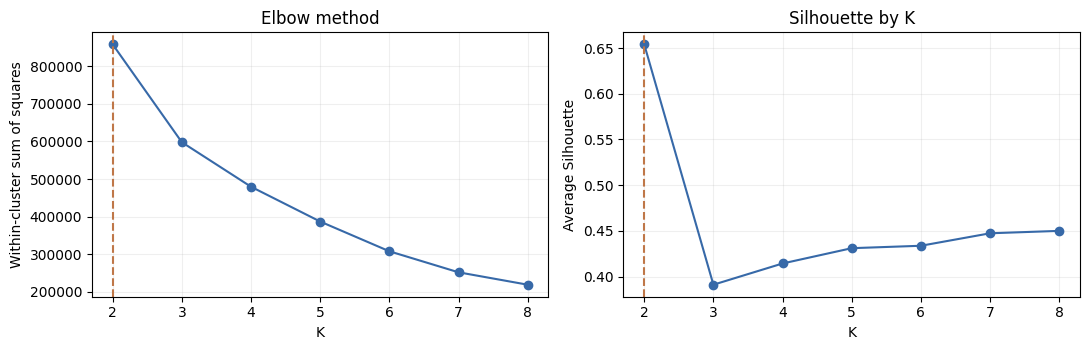

In [6]:
## Sample the data for training and evaluation
train_idx = rng.choice(len(rides), 30_000, replace=False)
eval_idx = rng.choice(len(rides), 1_200, replace=False)
X_train = X[train_idx]
X_eval = X[eval_idx]

k_rows = []
models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10, max_iter=100)
    model.fit(X_train)
    eval_labels = model.predict(X_eval)
    sample_labels = model.labels_
    max_group_share = np.bincount(sample_labels).max() / len(sample_labels) * 100
    k_rows.append({"K": k, "WSS (sample)": model.inertia_,
                   "Silhouette": silhouette_score(X_eval, eval_labels),
                   "Largest group %": max_group_share})
    models[k] = model
results_k = pd.DataFrame(k_rows)
display(results_k.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(results_k["K"], results_k["WSS (sample)"], "o-", color="#3769a8")
axes[0].axvline(SELECTED_K, linestyle="--", color="#bf7748")
axes[0].set(title="Elbow method", xlabel="K", ylabel="Within-cluster sum of squares")
axes[1].plot(results_k["K"], results_k["Silhouette"], "o-", color="#3769a8")
axes[1].axvline(SELECTED_K, linestyle="--", color="#bf7748")
axes[1].set(title="Silhouette by K", xlabel="K", ylabel="Average Silhouette")
plt.tight_layout()
plt.show()


In [7]:
## Refine the KMeans clustering with K=2
k = SELECTED_K
centers = models[k].cluster_centers_.copy()
for iteration in range(40):
    dist2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    labels0 = np.argmin(dist2, axis=1)
    counts = np.bincount(labels0, minlength=k)
    next_centers = np.column_stack([
        np.bincount(labels0, weights=X[:, j], minlength=k) / counts
        for j in range(2)
    ])
    change = np.max(np.linalg.norm(next_centers - centers, axis=1))
    centers = next_centers
    if change < 1e-6:
        break

labels0 = np.argmin(((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2), axis=1)
# Number clusters consistently by their west-to-east centre position.
order = np.argsort(centers[:, 0])
renumber = np.empty(k, dtype=int)
renumber[order] = np.arange(k)
centers = centers[order]
rides["cluster"] = renumber[labels0] + 1

centers_table = pd.DataFrame({
    "cluster": range(1, k + 1),
    "latitude": lat_reference + centers[:, 1] / 111.32,
    "longitude": lon_reference + centers[:, 0] / (111.32 * cos_lat)
})
cluster_counts = rides.groupby("cluster").size().rename("pickups").reset_index()
cluster_counts["share_pct"] = 100 * cluster_counts["pickups"] / len(rides)
display(cluster_counts.round(2))
display(centers_table.round(5))

quality_labels = np.argmin(((X_eval[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2), axis=1)
quality = {
    "Silhouette": silhouette_score(X_eval, quality_labels),
    "Calinski-Harabasz": calinski_harabasz_score(X_eval, quality_labels),
    "Davies-Bouldin": davies_bouldin_score(X_eval, quality_labels),
}
print("Quality measures on 1,200 evaluation points:")
display(pd.DataFrame([quality]).round(3))


,cluster,pickups,share_pct
0,1,953346,92.79
1,2,74036,7.21


,cluster,latitude,longitude
0,1,40.74016,-73.98388
1,2,40.72689,-73.81916


Quality measures on 1,200 evaluation points:


,Silhouette,Calinski-Harabasz,Davies-Bouldin
0,0.654,569.798,0.861


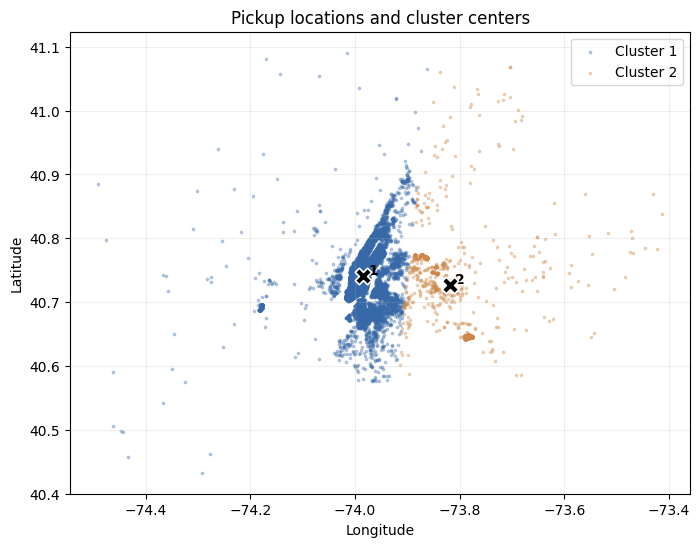

In [8]:
## Visualize the clusters and their centers
colors = {1: "#3769a8", 2: "#cc8747"}
plot_idx = rng.choice(len(rides), 18_000, replace=False)
plot_data = rides.iloc[plot_idx]
fig, ax = plt.subplots(figsize=(8, 6))
for cluster, group in plot_data.groupby("cluster"):
    ax.scatter(group["Lon"], group["Lat"], s=3, alpha=0.3,
               color=colors[cluster], label=f"Cluster {cluster}")
for _, row in centers_table.iterrows():
    ax.scatter(row["longitude"], row["latitude"], marker="X", s=140,
               color="black", edgecolor="white", linewidth=1.2, zorder=5)
    ax.text(row["longitude"] + 0.01, row["latitude"] + 0.003,
            str(int(row["cluster"])), weight="bold")
ax.set(title="Pickup locations and cluster centers", xlabel="Longitude", ylabel="Latitude")
ax.legend()
plt.show()


Busiest recorded hour in each cluster:


,cluster,hour,pickups
18,1,18,70084
44,2,20,5509


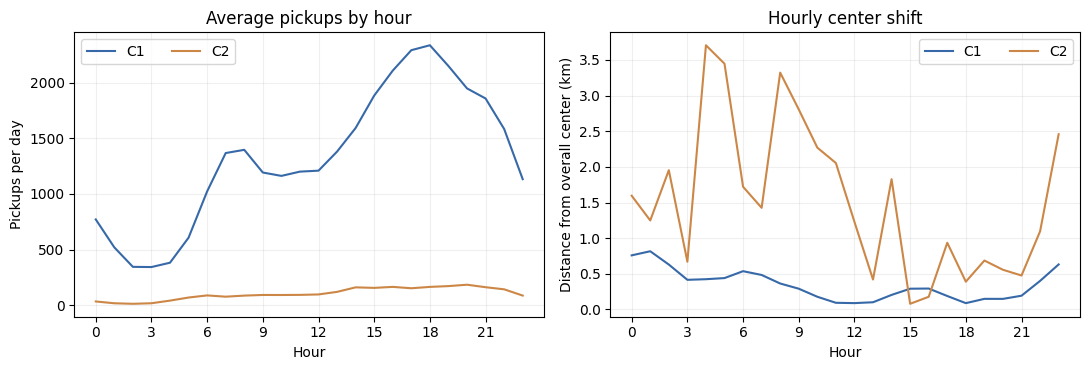

In [9]:
### Analyze the clusters by hour and day
rides["date"] = rides["datetime"].dt.floor("D")
rides["hour"] = rides["datetime"].dt.hour
hourly = (rides.groupby(["cluster", "hour"])
          .agg(pickups=("cluster", "size"), center_lat=("Lat", "mean"), center_lon=("Lon", "mean"))
          .reset_index())
daily = (rides.groupby(["cluster", "date"])
         .agg(pickups=("cluster", "size"), center_lat=("Lat", "mean"), center_lon=("Lon", "mean"))
         .reset_index())

for table in (hourly, daily):
    table["lat_ref"] = table["cluster"].map(centers_table.set_index("cluster")["latitude"])
    table["lon_ref"] = table["cluster"].map(centers_table.set_index("cluster")["longitude"])
    table["center_shift_km"] = np.sqrt(
        ((table["center_lat"] - table["lat_ref"]) * 111.32) ** 2 +
        ((table["center_lon"] - table["lon_ref"]) * 111.32 * cos_lat) ** 2
    )
    table.drop(columns=["lat_ref", "lon_ref"], inplace=True)

peak = hourly.loc[hourly.groupby("cluster")["pickups"].idxmax(), ["cluster", "hour", "pickups"]]
print("Busiest recorded hour in each cluster:")
display(peak.sort_values("cluster"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for c in range(1, k + 1):
    h = hourly[hourly["cluster"] == c]
    axes[0].plot(h["hour"], h["pickups"] / 30, label=f"C{c}", color=colors[c])
    axes[1].plot(h["hour"], h["center_shift_km"], label=f"C{c}", color=colors[c])
axes[0].set(title="Average pickups by hour", xlabel="Hour", ylabel="Pickups per day")
axes[1].set(title="Hourly center shift", xlabel="Hour", ylabel="Distance from overall center (km)")
for ax in axes:
    ax.legend(ncol=2)
    ax.set_xticks(range(0, 24, 3))
plt.tight_layout()
plt.show()


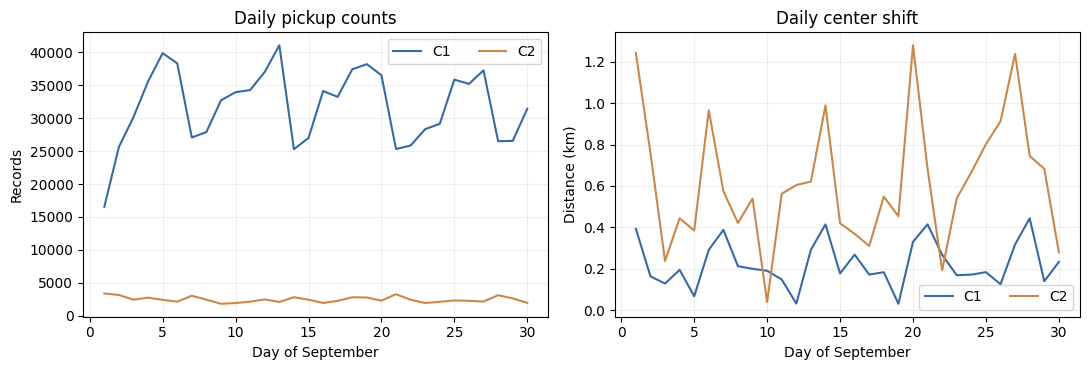

In [10]:
## Visualize daily patterns
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for c in range(1, k + 1):
    day = daily[daily["cluster"] == c]
    axes[0].plot(day["date"].dt.day, day["pickups"], label=f"C{c}", color=colors[c])
    axes[1].plot(day["date"].dt.day, day["center_shift_km"], label=f"C{c}", color=colors[c])
axes[0].set(title="Daily pickup counts", xlabel="Day of September", ylabel="Records")
axes[1].set(title="Daily center shift", xlabel="Day of September", ylabel="Distance (km)")
for ax in axes:
    ax.legend(ncol=2)
plt.tight_layout()
plt.show()


,cluster,method,MAE,WAPE_pct
1,1,Weekday mean,1717.43,5.42
4,2,Weekday mean,141.70,5.96


Overall WAPE on the 7 test days: 5.5%
Predicted pickup records, Oct 1–7: 241,831
Forecasts for October 1–7, 2014, by cluster:


cluster,1,2
date,,
2014-10-01,31624.0,2197.0
2014-10-02,35782.0,2513.0
2014-10-03,37574.0,2492.0
2014-10-04,38296.0,2181.0
2014-10-05,26046.0,3069.0
2014-10-06,24764.0,2674.0
2014-10-07,30447.0,2172.0


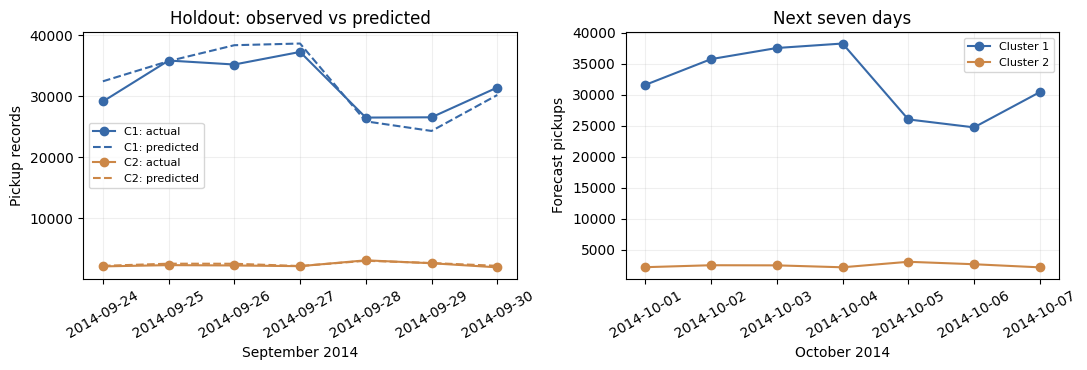

In [11]:
## Forecasting pickups for the first week of October
all_days = pd.date_range("2014-09-01", "2014-09-30", freq="D")
future_days = pd.date_range("2014-10-01", "2014-10-07", freq="D")
methods = ["Seasonal naive", "Weekday mean", "Last-day naive"]

def predict_history(history, future_dates, method):
    if method == "Seasonal naive":
        return np.array([history.loc[d - pd.Timedelta(days=7)] for d in future_dates], dtype=float)
    if method == "Weekday mean":
        return np.array([history.loc[history.index.dayofweek == d.dayofweek].mean()
                         for d in future_dates], dtype=float)
    if method == "Last-day naive":
        return np.repeat(float(history.iloc[-1]), len(future_dates))
    raise ValueError(method)

scores, checks, forecasts = [], [], []
for c in range(1, k + 1):
    s = (daily.loc[daily["cluster"] == c].set_index("date")["pickups"]
         .reindex(all_days).fillna(0).astype(float))
    train = s.loc[:"2014-09-23"]
    test = s.loc["2014-09-24":]
    trial = []
    for method in methods:
        prediction = predict_history(train, test.index, method)
        mae = np.abs(prediction - test.to_numpy()).mean()
        trial.append((method, mae))
        scores.append({"cluster": c, "method": method, "MAE": mae,
                       "WAPE_pct": 100 * np.abs(prediction - test.to_numpy()).sum() / test.sum() if test.sum() > 0 else np.nan})
    best_method = min(trial, key=lambda row: row[1])[0]
    for d, actual, predicted in zip(test.index, test.values, predict_history(train, test.index, best_method)):
        checks.append({"cluster": c, "date": d, "actual": actual, "predicted": predicted})
    for d, predicted in zip(future_days, predict_history(s, future_days, best_method)):
        forecasts.append({"cluster": c, "date": d, "method": best_method,
                          "forecast_pickups": max(0, predicted)})

scores = pd.DataFrame(scores)
checks = pd.DataFrame(checks)
forecasts = pd.DataFrame(forecasts)
best_scores = scores.loc[scores.groupby("cluster")["MAE"].idxmin()].sort_values("cluster")
display(best_scores.round(2))

wape_total = 100 * np.abs(checks["actual"] - checks["predicted"]).sum() / checks["actual"].sum()
print(f"Overall WAPE on the 7 test days: {wape_total:.1f}%")
print(f"Predicted pickup records, Oct 1–7: {forecasts['forecast_pickups'].sum():,.0f}")

print("Forecasts for October 1–7, 2014, by cluster:")
display(forecasts.pivot(index="date", columns="cluster", values="forecast_pickups").round(0))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for c in range(1, k + 1):
    chk = checks[checks["cluster"] == c]
    axes[0].plot(chk["date"], chk["actual"], "o-", label=f"C{c}: actual", color=colors[c])
    axes[0].plot(chk["date"], chk["predicted"], "--", label=f"C{c}: predicted", color=colors[c])
    f = forecasts[forecasts["cluster"] == c]
    axes[1].plot(f["date"], f["forecast_pickups"], "o-", label=f"Cluster {c}", color=colors[c])
axes[0].set(title="Holdout: observed vs predicted", xlabel="September 2014", ylabel="Pickup records")
axes[1].set(title="Next seven days", xlabel="October 2014", ylabel="Forecast pickups")
for ax in axes:
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.show()
